# 007 Medium — Moments

`P_max, cN2_max, L_inj, dip_frac, x_of` + `plane_mm` → 6 centroids, 6 widths, charge

## Setup

In [1]:
from xgboost import XGBRegressor  # before torch (OpenMP clash on macOS)

import copy
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, train_test_split
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import StandardScaler

from pallas_score import normalised_to_physical, physical_to_normalised, score_submission
from physics_formulas import electrons_background, energy_gain_MeV, m3_to_cm3, species_B

torch.set_num_threads(1)

PACK = "/Users/netanmangal/Documents/netanmangal/ganil-artifact-hackathon-2026/challenges/surrogate-models/full-data"
TASK = "moments"
TARGETS = ['mean_zeta_um', 'mean_y_um', 'mean_z_um', 'mean_ux', 'mean_uy', 'mean_uz', 'sigma_zeta', 'sigma_y', 'sigma_z', 'sigma_ux', 'sigma_uy', 'sigma_uz', 'q_tot_pC']
FEATURES = ['P_max', 'cN2_max', 'L_inj', 'dip_frac', 'x_of', 'plane_mm']
EPOCHS = 100
BATCH = 512
XGB_TREES = 200
HIDDEN = [512, 1024, 128]
LOSS = nn.MSELoss()

data = pd.read_parquet(f"{PACK}/campaign_B_moments.parquet")
data = data[(data.group == "all") & (data.q_tot_pC > 0) & (data.ess >= 10)].copy()
data["config"] = data.sim_id.str.removeprefix("Config_").astype(int)
data["sigma_zeta"] = np.sqrt(data.cov_00)
data["sigma_y"] = np.sqrt(data.cov_11)
data["sigma_z"] = np.sqrt(data.cov_22)
data["sigma_ux"] = np.sqrt(data.cov_33)
data["sigma_uy"] = np.sqrt(data.cov_44)
data["sigma_uz"] = np.sqrt(data.cov_55)
test_inputs = pd.read_parquet(f"{PACK}/test_moments_planes.parquet")
configs = data.config.unique()


def features(frame):
    X = frame[FEATURES].copy()
    X["dz"] = X.plane_mm - (X.L_inj + 3.2)
    X["in_plasma"] = (X.dz <= 0).astype(float)
    X["n_e"] = X.P_max * (1 - 0.3 * X.cN2_max)
    X["n_N2"] = X.P_max * X.cN2_max
    X["lambda_p"] = 1 / np.sqrt(X.n_e)
    return X.to_numpy()


def targets(frame):
    columns = []
    for t in TARGETS:
        columns.append(physical_to_normalised(t, frame[t]))
    return np.column_stack(columns)


def physical(pred):
    out = pd.DataFrame()
    for i, t in enumerate(TARGETS):
        out[t] = normalised_to_physical(t, pred[:, i])
    return out


def score(pred, frame, zone=None):
    pred = physical(pred)
    pred.insert(0, "plane_mm", frame.plane_mm.to_numpy())
    pred.insert(0, "config", frame.config.to_numpy())
    return score_submission(pred, frame[["config", "plane_mm", "L_inj"] + TARGETS], zone=zone)


train_configs, test_configs = train_test_split(configs, test_size=0.2, random_state=0)
train = data[data.config.isin(train_configs)]
test = data[data.config.isin(test_configs)]
print(f"{len(data):,} rows, {len(configs):,} configs: {len(train_configs):,} train / {len(test_configs):,} test")

96,965 rows, 4,986 configs: 3,988 train / 998 test


## Random forest

In [2]:
rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0)
rf.fit(features(train), targets(train))
score(rf.predict(features(test)), test)

{'mean_zeta_um': 0.7986975470369092,
 'mean_y_um': 0.21796638875902985,
 'mean_z_um': -0.04327110041463911,
 'mean_ux': 0.9524014117646283,
 'mean_uy': 0.16231032379729637,
 'mean_uz': 0.036002905621506986,
 'sigma_zeta': 0.8779151060913886,
 'sigma_y': 0.8209749709634464,
 'sigma_z': 0.806062165364822,
 'sigma_ux': 0.8800271264635334,
 'sigma_uy': 0.8455150289755016,
 'sigma_uz': 0.7231506193578026,
 'q_tot_pC': 0.8992566955039162,
 'mean': 0.6136160914834725,
 'n_rows': 19395,
 'n_z_scored': 20,
 'n_z_dropped': 0}

## XGBoost

In [3]:
xgb = MultiOutputRegressor(XGBRegressor(n_estimators=XGB_TREES, learning_rate=0.05, max_depth=7,
                                        subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=0))
xgb.fit(features(train), targets(train))
score(xgb.predict(features(test)), test)

{'mean_zeta_um': 0.7895047236983453,
 'mean_y_um': 0.11974945510189883,
 'mean_z_um': -0.098003127416731,
 'mean_ux': 0.9601006825981494,
 'mean_uy': 0.06717149220774643,
 'mean_uz': 0.02402221055200293,
 'sigma_zeta': 0.9188833242630772,
 'sigma_y': 0.8881382598310232,
 'sigma_z': 0.8656363510756621,
 'sigma_ux': 0.918043206796783,
 'sigma_uy': 0.9043575842791226,
 'sigma_uz': 0.7510375436539689,
 'q_tot_pC': 0.9712192686567183,
 'mean': 0.6215277673305976,
 'n_rows': 19395,
 'n_z_scored': 20,
 'n_z_dropped': 0}

## MLP

In [4]:
def build_mlp(n_inputs):
    return nn.Sequential(
        nn.Linear(n_inputs, HIDDEN[0]), nn.ReLU(),
        nn.Linear(HIDDEN[0], HIDDEN[1]), nn.ReLU(),
        nn.Linear(HIDDEN[1], HIDDEN[2]), nn.ReLU(),
        nn.Linear(HIDDEN[2], len(TARGETS)),
    )


def fit_model(train, val, seed, build=build_mlp, epochs=EPOCHS):
    torch.manual_seed(seed)
    scaler = StandardScaler().fit(features(train))
    y_mean = targets(train).mean(0)
    y_std = targets(train).std(0)

    X = torch.tensor(scaler.transform(features(train)), dtype=torch.float32)
    y = torch.tensor((targets(train) - y_mean) / y_std, dtype=torch.float32)
    if val is not None:
        X_val = torch.tensor(scaler.transform(features(val)), dtype=torch.float32)
        y_val = torch.tensor((targets(val) - y_mean) / y_std, dtype=torch.float32)

    net = build(X.shape[1])
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)

    val_loss = []
    best_net = net
    for epoch in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            loss = LOSS(net(X[idx]), y[idx])
            loss.backward()
            opt.step()
        sched.step()
        if val is not None:
            with torch.no_grad():
                val_loss.append(LOSS(net(X_val), y_val).item())
            if val_loss[-1] == min(val_loss):
                best_net = copy.deepcopy(net)

    return {"net": best_net, "scaler": scaler, "y_mean": y_mean, "y_std": y_std, "val_loss": val_loss}


def fit_mlp(train, val, seed):
    return fit_model(train, val, seed)


def predict_mlp(model, X):
    X = torch.tensor(model["scaler"].transform(X), dtype=torch.float32)
    with torch.no_grad():
        out = model["net"](X).numpy()
    return out * model["y_std"] + model["y_mean"]


def predict_ensemble(models, X):
    preds = []
    for model in models:
        preds.append(predict_mlp(model, X))
    return np.mean(preds, axis=0)


mlp = fit_mlp(train, test, seed=0)
print(f"best val loss {min(mlp['val_loss']):.4f} at epoch {np.argmin(mlp['val_loss']) + 1}")
score(predict_mlp(mlp, features(test)), test)

best val loss 0.2184 at epoch 76


{'mean_zeta_um': 0.9739200727224948,
 'mean_y_um': 0.5467206204887579,
 'mean_z_um': 0.10276285813869757,
 'mean_ux': 0.9911707142882947,
 'mean_uy': 0.5605695213150035,
 'mean_uz': 0.4665493301610143,
 'sigma_zeta': 0.9629157622755184,
 'sigma_y': 0.9627670555890067,
 'sigma_z': 0.946220792674131,
 'sigma_ux': 0.9706206734005713,
 'sigma_uy': 0.9415141439104269,
 'sigma_uz': 0.8796883736783132,
 'q_tot_pC': 0.9976706779866646,
 'mean': 0.792545430509915,
 'n_rows': 19395,
 'n_z_scored': 20,
 'n_z_dropped': 0}

## MLP ensemble

Three seeds averaged.

In [5]:
ensemble = [mlp]
for seed in (1, 2):
    ensemble.append(fit_mlp(train, test, seed))
score(predict_ensemble(ensemble, features(test)), test)

{'mean_zeta_um': 0.980369887350688,
 'mean_y_um': 0.5898464749336134,
 'mean_z_um': 0.1252574140988365,
 'mean_ux': 0.9950072658701775,
 'mean_uy': 0.6055934566723546,
 'mean_uz': 0.500893455830026,
 'sigma_zeta': 0.9667366198287235,
 'sigma_y': 0.9646847082077832,
 'sigma_z': 0.950736088157672,
 'sigma_ux': 0.9746891530491618,
 'sigma_uy': 0.9451533382118124,
 'sigma_uz': 0.8920654137209962,
 'q_tot_pC': 0.9984124991623056,
 'mean': 0.8068804442380115,
 'n_rows': 19395,
 'n_z_scored': 20,
 'n_z_dropped': 0}

## Cross validation

In [6]:
rows = []
curves = []
for k, (train_idx, val_idx) in enumerate(KFold(5, shuffle=True, random_state=0).split(configs)):
    tr = data[data.config.isin(configs[train_idx])]
    va = data[data.config.isin(configs[val_idx])]

    rf_k = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0)
    rf_k.fit(features(tr), targets(tr))
    xgb_k = MultiOutputRegressor(XGBRegressor(n_estimators=XGB_TREES, learning_rate=0.05, max_depth=7,
                                              subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=0))
    xgb_k.fit(features(tr), targets(tr))
    mlp_k = fit_mlp(tr, va, seed=k)
    curves.append(mlp_k["val_loss"])

    rows.append({
        "rf": score(rf_k.predict(features(va)), va)["mean"],
        "xgb": score(xgb_k.predict(features(va)), va)["mean"],
        "mlp": score(predict_mlp(mlp_k, features(va)), va)["mean"],
    })
    print(f"fold {k}  mlp best val loss {min(mlp_k['val_loss']):.4f} at epoch {np.argmin(mlp_k['val_loss']) + 1}")

cv = pd.DataFrame(rows)
cv.loc["mean"] = cv.mean()
cv.loc["std"] = cv.iloc[:-1].std()
cv.round(4)

fold 0  mlp best val loss 0.2184 at epoch 76


fold 1  mlp best val loss 0.1548 at epoch 77


fold 2  mlp best val loss 0.3008 at epoch 35


fold 3  mlp best val loss 0.2763 at epoch 40


fold 4  mlp best val loss 0.1800 at epoch 53


,rf,xgb,mlp
0,0.6136,0.6215,0.7925
1,0.5827,0.6030,0.7829
2,0.6035,0.6080,0.7720
3,0.5965,0.6098,0.7517
4,0.5927,0.6144,0.7643
mean,0.5978,0.6113,0.7727
std,0.0116,0.0070,0.0159


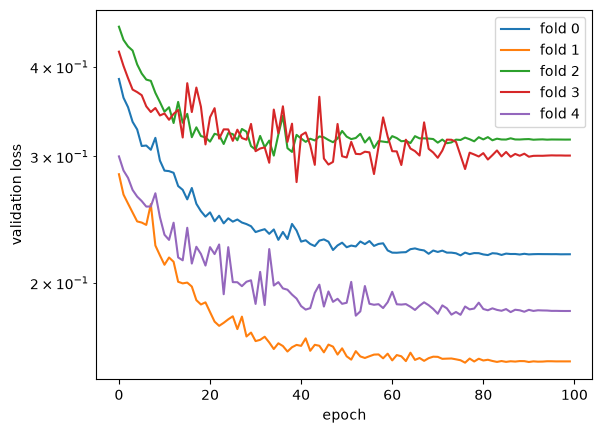

In [7]:
for k, curve in enumerate(curves):
    plt.plot(curve, label=f"fold {k}")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.legend()
plt.show()

## Submission

Centroids renamed without `_um`, as the organisers want.

In [8]:
submission = physical(predict_ensemble(ensemble, features(test_inputs)))
submission.insert(0, "plane_mm", test_inputs.plane_mm.to_numpy())
submission.insert(0, "config", test_inputs.config.to_numpy())
submission = submission.rename(columns={"mean_zeta_um": "mean_zeta", "mean_y_um": "mean_y", "mean_z_um": "mean_z"})
submission.to_csv("submission_moments.csv", index=False)
print(f"wrote submission_moments.csv ({len(submission):,} rows)")

wrote submission_moments.csv (3,213 rows)


## Save for the Hopsworks registry

In [9]:
name = f"lsr_{TASK}_mlp"
path = f"models/{name}"
os.makedirs(path, exist_ok=True)
for seed, model in enumerate(ensemble):
    torch.save(model["net"].state_dict(), f"{path}/model_seed{seed}.pt")
    np.savez(f"{path}/scaler_seed{seed}.npz", x_mean=model["scaler"].mean_, x_std=model["scaler"].scale_,
             y_mean=model["y_mean"], y_std=model["y_std"])

scores = score(predict_ensemble(ensemble, features(test)), test)
metrics = {}
for t in TARGETS:
    metrics[f"holdout_r2_{t}"] = round(scores[t], 4)
metrics["holdout_mean_r2"] = round(scores["mean"], 4)
metrics["cv_mean_r2"] = round(float(cv.loc["mean", "mlp"]), 4)

json.dump({"task": TASK, "model": "mlp", "features": FEATURES, "targets": TARGETS, "metrics": metrics},
          open(f"{path}/meta.json", "w"), indent=1)
metrics

{'holdout_r2_mean_zeta_um': 0.9804,
 'holdout_r2_mean_y_um': 0.5898,
 'holdout_r2_mean_z_um': 0.1253,
 'holdout_r2_mean_ux': 0.995,
 'holdout_r2_mean_uy': 0.6056,
 'holdout_r2_mean_uz': 0.5009,
 'holdout_r2_sigma_zeta': 0.9667,
 'holdout_r2_sigma_y': 0.9647,
 'holdout_r2_sigma_z': 0.9507,
 'holdout_r2_sigma_ux': 0.9747,
 'holdout_r2_sigma_uy': 0.9452,
 'holdout_r2_sigma_uz': 0.8921,
 'holdout_r2_q_tot_pC': 0.9984,
 'holdout_mean_r2': 0.8069,
 'cv_mean_r2': 0.7727}

## Comparison

In [10]:
table = pd.DataFrame({
    "rf": score(rf.predict(features(test)), test),
    "xgb": score(xgb.predict(features(test)), test),
    "mlp": score(predict_mlp(mlp, features(test)), test),
    "ensemble": score(predict_ensemble(ensemble, features(test)), test),
})
table.T[TARGETS + ["mean"]].round(3)

,mean_zeta_um,mean_y_um,mean_z_um,mean_ux,mean_uy,mean_uz,sigma_zeta,sigma_y,sigma_z,sigma_ux,sigma_uy,sigma_uz,q_tot_pC,mean
rf,0.799,0.218,-0.043,0.952,0.162,0.036,0.878,0.821,0.806,0.880,0.846,0.723,0.899,0.614
xgb,0.790,0.120,-0.098,0.960,0.067,0.024,0.919,0.888,0.866,0.918,0.904,0.751,0.971,0.622
mlp,0.974,0.547,0.103,0.991,0.561,0.467,0.963,0.963,0.946,0.971,0.942,0.880,0.998,0.793
ensemble,0.980,0.590,0.125,0.995,0.606,0.501,0.967,0.965,0.951,0.975,0.945,0.892,0.998,0.807
